# 🎓 第7章 第4课：结业项目 —— 多因子 Smart Beta 组合

**本节目标**：把前六章 + 本章工具串起来，完成一个可复现的结业项目：

1. 用多因子复合分数选股；
2. 分数加权，构建 Smart Beta 组合；
3. 对比等权基准，做绩效、换手、风格回归、风险归因；
4. 写一份“结业报告”摘要。

> 这是教学项目，不是投资建议；示例面板为教学数据，结果不代表真实 A 股。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.anomalies import rolling_ivol
from factor_zero.portfolio import (
    FACTOR_ORDER, build_style_exposures, factor_covariance,
    specific_variance, portfolio_risk, min_variance_weights,
    max_sharpe_weights, style_regression, smart_beta_weights,
)
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 策略定义

- 复合分数：价值 + 质量 + 动量 − 换手 − 投资；
- 每月选分数最高的 20%；
- 分数加权（负分数截断为 0）；
- 持有下个月，月度调仓。

In [2]:
panel = load_ashare_panel()
ret = panel['ret']
factors = build_factor_returns(panel, n_groups=10)
def z(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
score = z(panel['bm']) + z(panel['roe']) + z(panel['momentum']) - z(panel['turnover']) - z(panel['investment'])
dates = ret.index
port, bench, weight_hist = [], [], {}
for t in range(len(dates) - 1):
    d, dn = dates[t], dates[t + 1]
    s = score.loc[d].dropna()
    if len(s) < 20:
        continue
    top = s.sort_values(ascending=False).head(max(10, int(len(s) * 0.2))).index
    w = smart_beta_weights(s.loc[top], method='score')
    weight_hist[dn] = w
    port.append(float((ret.loc[dn, top] * w).sum()))
    bench.append(float(ret.loc[dn].mean()))
idx = dates[1:1 + len(port)]
port = pd.Series(port, index=idx, name='多因子组合')
bench = pd.Series(bench, index=idx, name='等权基准')
weights = pd.DataFrame(weight_hist).T.fillna(0.0)
print('回测月份:', len(port), '| 持仓股票数（平均）:', int((weights > 0).sum(axis=1).mean()))

回测月份: 70 | 持仓股票数（平均）: 16


## 2) 绩效对比

In [3]:
perf = pd.DataFrame({
    '多因子组合': factor_summary(port),
    '等权基准': factor_summary(bench),
}).T
perf.columns = ['年化收益', '年化波动', 'Sharpe', 'NW t', '最大回撤', '胜率']
perf.round(4)

,年化收益,年化波动,Sharpe,NW t,最大回撤,胜率
多因子组合,0.2234,0.1958,1.1409,3.2573,-0.1538,0.6429
等权基准,0.1772,0.1968,0.9006,2.3800,-0.1987,0.5571


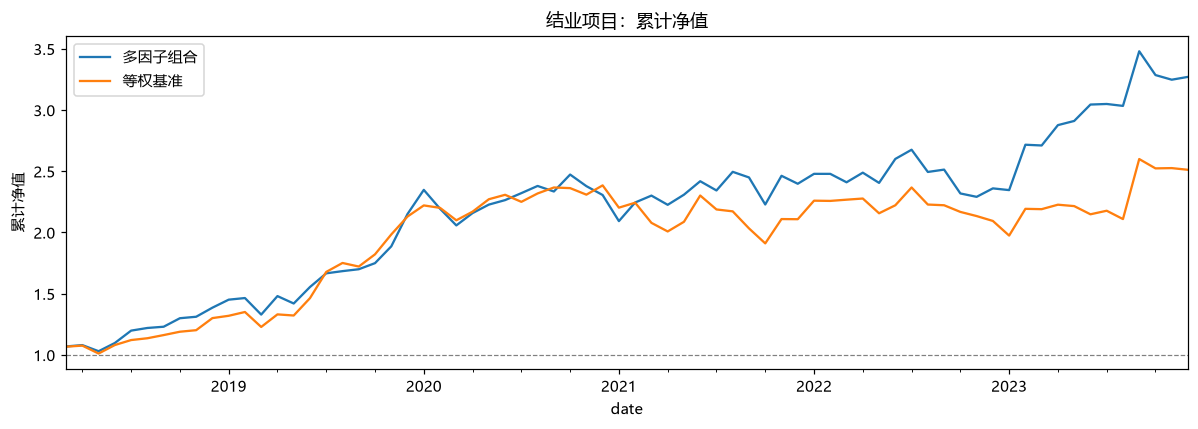

In [4]:
((1 + pd.DataFrame({'多因子组合': port, '等权基准': bench})).cumprod()).plot(
    figsize=(11, 4), title='结业项目：累计净值'
)
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值')
plt.tight_layout(); plt.show()

## 3) 换手率与风格暴露

In [5]:
turnover = 0.5 * weights.diff().abs().sum(axis=1)
print(f'平均月度换手率: {turnover.mean()*100:.1f}%')
print(f'年化换手率（近似）: {turnover.mean()*12*100:.0f}%')
alpha, betas, r2, resid = style_regression(port, factors[FACTOR_ORDER])
print(f'风格回归 R²: {r2:.3f}   α（月）: {alpha*100:.3f}%')
betas.round(3)

平均月度换手率: 15.1%
年化换手率（近似）: 181%
风格回归 R²: 0.071   α（月）: 1.474%


MKT     0.170
SMB     0.092
HML     0.097
WML    -0.064
RMW     0.033
CMA    -0.067
TURN   -0.028
dtype: float64

## 4) 风险归因（最后一期）

In [6]:
beta = ret.rolling(24).cov(panel['market']).div(panel['market'].rolling(24).var(), axis=0)
ivol = rolling_ivol(ret, factors[FACTOR_ORDER], window=36)
date = ret.index[-1]
B = build_style_exposures(panel, date, beta)
fcov = factor_covariance(factors, date, window=36)
sv = specific_variance(ivol, date, B.index)
w_last = weights.iloc[-1].reindex(B.index).fillna(0.0)
risk = portfolio_risk(w_last, B, fcov, sv)
contrib = risk['factor_contrib'].copy(); contrib['特质'] = risk['specific_contrib']
print(f'总波动: {risk["total_vol"]*100:.2f}%  因子: {risk["factor_vol"]*100:.2f}%  特质: {risk["specific_vol"]*100:.2f}%')
(contrib * 100).round(2)

总波动: 69.90%  因子: 69.58%  特质: 6.70%


MKT      2.41
SMB      9.68
HML      5.02
WML     32.90
RMW      4.06
CMA      2.94
TURN    12.24
特质       0.64
dtype: float64

> ⚠️ **注意模型错位**：这里风险模型给出的总波动（约 70%）远高于回测波动（约 20%）。
> 这是“迷你风险模型”的局限：z-score 暴露 × 多空因子收益会高估集中组合的因子风险。
> 真实 Barra 模型需要纯因子组合、去相关、特征值调整等。风险模型误差本身也是实践中的大问题。


## 5) 结业报告清单

- [ ] 策略定义：因子、选股比例、加权方式、调仓频率；
- [ ] 数据说明：来源、区间、清洗规则、已知偏差；
- [ ] 绩效：年化收益、波动、Sharpe、NW t、最大回撤、胜率；
- [ ] 基准：等权/市值加权/因子基准；
- [ ] 换手率与交易成本：扣费前后、容量；
- [ ] 风格暴露：Sharpe 回归的 β、R²、α；
- [ ] 风险归因：因子贡献 + 特质贡献；
- [ ] 稳健性：分区间、换窗口、换参数、样本外；
- [ ] 结论与局限：哪些是数据窥探/过拟合/样本特定。

## ✋ 试一试

1. 把选股比例从 20% 改成 10%，换手率和绩效怎么变？
2. 把分数加权改成等权，集中度/换手/绩效怎么变？
3. 把复合分数里的动量去掉，结果还稳吗？

## ✅ 本节小结

- 结业项目 = 数据 → 因子 → 组合 → 绩效 → 归因 → 报告；
- 绩效好不代表可复制：要看换手、成本、容量、稳健性；
- 风格回归和风险归因帮助解释“收益/风险从哪里来”；
- 示例数据为教学面板，结论不能直接外推。

> 🎓 恭喜你完成《Factor-Investing-from-Zero》七章课程！